# iPSC-EC CRT QQ export: full covariate adjustment

This notebook runs the d0–d3 iPSC-EC CRT QQ export using the requested covariates:

- `pct_counts_mt`
- `biological_sample`
- `total_counts`
- `guides_per_cell`
- `guide_umi_counts`
- `n_genes_by_counts`

`biological_sample` is one-hot encoded with one reference level dropped. The count-like covariates are `log1p` transformed. The notebook writes the backend script into the current directory, runs it, validates the covariates recorded in each day's config, and saves Illustrator-editable QQ plots as PDF/SVG/EPS files.


In [ ]:
from pathlib import Path
import json
import os
import shlex
import subprocess
import sys

# Set thread-count defaults before NumPy/SciPy get imported by the backend.
for variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ.setdefault(variable, "1")

PROGRAMDE_ROOT = "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE"
DATA_DIR = "/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data"
CNMF_DIR = "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all"
GUIDE_LONG_TEMPLATE = "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv"

OUT_DIR = "results/ipsc_ec_qq_exports_full_covariates"
DAYS = ["d0", "d1", "d2", "d3"]
K = 50
DENSITY_THRESHOLD = "0_2"
B = 10000
N_JOBS = int(os.environ.get("SLURM_CPUS_PER_TASK", "8"))
NTC_LABELS = ["SAFE", "non-targeting", "NTC"]

# Rerun controls. Keep OVERWRITE=True when changing covariates.
REQUIRE_COVARIATES = True
OVERWRITE = True
NO_BACKEND_PLOTS = True   # plotnine Illustrator files are made in later cells
NO_SKEW = False           # set True only if you want empirical p-values only

MODEL_ROOT = Path(OUT_DIR) / f"k_{K}.dt_{DENSITY_THRESHOLD}"
print("Output root:", MODEL_ROOT)
print("N_JOBS:", N_JOBS)


Output root: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2
N_JOBS: 8


## Write the backend script

Run this cell once before the dry run or full run. It overwrites `iPSC_EC_QQ_export_all_days.py` in the current working directory with the full-covariate version.

In [2]:
%%writefile iPSC_EC_QQ_export_all_days.py
#!/usr/bin/env python
"""
Export iPSC-EC CRT QQ-plot p-value points for d0, d1, d2, and d3.

This version uses the full requested covariate adjustment set:
pct_counts_mt, biological_sample, total_counts, guides_per_cell,
guide_umi_counts, and n_genes_by_counts.

This script adapts the simple QQ export pattern from the IP/GV K30 dt2
bundle to the iPSC-EC notebooks.  It uses the source paths and setup used in
qq_sweep_test.ipynb and ipsc_ec_qq.ipynb:

  * H5MU source files: {day}_normalized_gex_and_guide.h5mu
  * cNMF usage files: *.usages.k_{K}.dt_{density_threshold}.consensus.txt
  * guide assignment long tables: {day}_grna_assignments_long.csv

The main exported files are per-day CSVs containing the exact p-values and the
ranked expected/observed -log10(p) coordinates needed to replot the QQ plots.
"""

from __future__ import annotations

# Set thread-count defaults before importing NumPy/SciPy.
import os

for _variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ.setdefault(_variable, "1")

import argparse
import inspect
import json
import re
import sys
import time
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path
from types import SimpleNamespace
from typing import Any, Iterable

import numpy as np
import pandas as pd


DEFAULT_PROGRAMDE_ROOT = "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE"
DEFAULT_DATA_DIR = (
    "/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/"
    "2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data"
)
DEFAULT_CNMF_DIR = (
    "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/"
    "012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/"
    "012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all"
)
DEFAULT_GUIDE_LONG_TEMPLATE = (
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "{day}_sceptre_transfer/{day}_grna_assignments_long.csv"
)
DEFAULT_DAYS = ["d0", "d1", "d2", "d3"]
DEFAULT_NTC_LABELS = ["SAFE", "non-targeting", "NTC"]


@dataclass
class DayRunSummary:
    day: str
    status: str
    output_dir: str
    h5mu_path: str | None = None
    usage_path: str | None = None
    guide_long_csv: str | None = None
    n_cells: int | None = None
    n_programs: int | None = None
    n_guides: int | None = None
    n_covariates: int | None = None
    matched_usage_cells: int | None = None
    n_observed_target_empirical_points: int | None = None
    n_ntc_pseudotarget_empirical_points: int | None = None
    n_observed_target_skew_points: int | None = None
    n_ntc_pseudotarget_skew_points: int | None = None
    message: str | None = None


def safe_name(value: object) -> str:
    """Return a filesystem-safe label."""
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("_") or "value"


def normalize_density_token(value: object) -> str:
    """Normalize density threshold labels to the dt token used by cNMF filenames."""
    text = str(value).strip()
    text = re.sub(r"^dt[_-]?", "", text, flags=re.IGNORECASE)
    text = text.replace(".", "_").replace("-", "_")
    text = re.sub(r"_+", "_", text).strip("_")
    if not text:
        raise ValueError("Density threshold token is empty.")
    return text


def model_tag(k: int, density_token: str) -> str:
    return f"k_{k}.dt_{density_token}"


def read_table_auto(path: Path) -> pd.DataFrame:
    """Read TSV/CSV files with a conservative delimiter guess."""
    suffix = path.suffix.lower()
    if suffix in {".tsv", ".txt"}:
        return pd.read_csv(path, sep="\t")
    if suffix == ".csv":
        return pd.read_csv(path)
    return pd.read_csv(path, sep=None, engine="python")


def load_programde(programde_root: str | None) -> SimpleNamespace:
    """Import programDE functions after adding the requested repository path."""
    if programde_root:
        root = str(Path(programde_root).expanduser())
        if root not in sys.path:
            sys.path.insert(0, root)

    from src.sceptre import (  # type: ignore
        build_ntc_group_inputs,
        crt_pvals_for_ntc_groups_ensemble,
        crt_pvals_for_ntc_groups_ensemble_skew,
        make_ntc_groups_ensemble,
        prepare_crt_inputs,
        run_all_genes_union_crt,
    )

    try:
        from src.sceptre import compute_ntc_group_null_pvals_parallel  # type: ignore
    except (ImportError, AttributeError):
        compute_ntc_group_null_pvals_parallel = None

    try:
        from src.sceptre import limit_threading  # type: ignore

        limit_threading()
    except (ImportError, AttributeError):
        pass

    try:
        from src.visualization import qq_plot_ntc_pvals  # type: ignore
    except (ImportError, AttributeError):
        qq_plot_ntc_pvals = None

    return SimpleNamespace(
        build_ntc_group_inputs=build_ntc_group_inputs,
        crt_pvals_for_ntc_groups_ensemble=crt_pvals_for_ntc_groups_ensemble,
        crt_pvals_for_ntc_groups_ensemble_skew=crt_pvals_for_ntc_groups_ensemble_skew,
        make_ntc_groups_ensemble=make_ntc_groups_ensemble,
        prepare_crt_inputs=prepare_crt_inputs,
        run_all_genes_union_crt=run_all_genes_union_crt,
        compute_ntc_group_null_pvals_parallel=compute_ntc_group_null_pvals_parallel,
        qq_plot_ntc_pvals=qq_plot_ntc_pvals,
    )


def resolve_modality(mdata: Any, preferred: str | None, fallbacks: list[str], label: str) -> str:
    """Resolve a modality name in a MuData object."""
    modalities = list(mdata.mod.keys())
    candidates = []
    if preferred:
        candidates.append(preferred)
    candidates.extend(fallbacks)

    for candidate in candidates:
        if candidate in mdata.mod:
            return candidate

    lowered = {name.lower(): name for name in modalities}
    for candidate in candidates:
        if candidate and candidate.lower() in lowered:
            return lowered[candidate.lower()]

    raise KeyError(
        f"Could not find {label} modality. Tried {candidates}; available modalities: {modalities}"
    )


def infer_guide2gene_from_names(
    guide_names: Iterable[str],
    ntc_labels: list[str],
) -> dict[str, str]:
    """Infer guide-to-target names using the ipsc_ec_qq.ipynb split rule."""
    labels_lower = {label.lower(): label for label in ntc_labels}
    mapping: dict[str, str] = {}
    for guide in map(str, guide_names):
        cleaned = guide.strip()
        lowered = cleaned.lower()
        matched_control = None
        for label_lower, label in labels_lower.items():
            if (
                lowered == label_lower
                or lowered.startswith(label_lower + "_")
                or lowered.startswith(label_lower + "-")
                or lowered.startswith(label_lower + ".")
            ):
                matched_control = label
                break
        mapping[guide] = matched_control if matched_control is not None else cleaned.split("_", 1)[0]
    return mapping


def load_guide2gene_metadata(
    path: Path,
    guide_names: list[str],
    guide_col: str | None,
    target_col: str | None,
) -> dict[str, str]:
    """Optionally load guide-to-target mapping from a metadata table."""
    table = read_table_auto(path)
    normalized_columns = {column.lower().replace(" ", "_"): column for column in table.columns}

    guide_candidates = [
        guide_col,
        "guide_name",
        "guide_id",
        "guide",
        "grna",
        "grna_name",
        "grna_id",
        "sgrna",
        "protospacer",
    ]
    target_candidates = [
        target_col,
        "target_name",
        "target",
        "gene",
        "gene_symbol",
        "symbol",
        "grna_target",
    ]

    resolved_guide_col = None
    for candidate in guide_candidates:
        if not candidate:
            continue
        key = candidate.lower().replace(" ", "_")
        if key in normalized_columns:
            resolved_guide_col = normalized_columns[key]
            break

    resolved_target_col = None
    for candidate in target_candidates:
        if not candidate:
            continue
        key = candidate.lower().replace(" ", "_")
        if key in normalized_columns and normalized_columns[key] != resolved_guide_col:
            resolved_target_col = normalized_columns[key]
            break

    if resolved_guide_col is None or resolved_target_col is None:
        raise KeyError(
            "Could not infer guide/target columns in guide metadata. "
            f"Columns were: {list(table.columns)}. "
            "Use --guide-metadata-guide-col and --guide-metadata-target-col."
        )

    raw_mapping = dict(
        zip(
            table[resolved_guide_col].astype(str),
            table[resolved_target_col].astype(str),
        )
    )
    return {guide: raw_mapping[guide] for guide in guide_names if guide in raw_mapping}


def build_guide2gene(
    guide_names: list[str],
    ntc_labels: list[str],
    metadata_tsv: str | None,
    guide_col: str | None,
    target_col: str | None,
) -> dict[str, str]:
    """Build guide-to-target mapping, defaulting to guide_name.split('_', 1)[0]."""
    mapping = infer_guide2gene_from_names(guide_names, ntc_labels)

    if metadata_tsv:
        metadata_path = Path(metadata_tsv).expanduser()
        if metadata_path.exists():
            try:
                metadata_mapping = load_guide2gene_metadata(
                    metadata_path,
                    guide_names,
                    guide_col,
                    target_col,
                )
                mapping.update(metadata_mapping)
                print(
                    f"guide metadata: mapped {len(metadata_mapping):,}/{len(guide_names):,} guides "
                    f"from {metadata_path}"
                )
            except Exception as exc:  # keep fallback mapping usable
                warnings.warn(
                    f"Guide metadata {metadata_path} could not be used ({exc}). "
                    "Falling back to guide_name.split('_', 1)[0]."
                )
        else:
            warnings.warn(
                f"Guide metadata file {metadata_path} was not found. "
                "Falling back to guide_name.split('_', 1)[0]."
            )
    return mapping


def h5mu_path_for_day(data_dir: Path, day: str) -> Path:
    return data_dir / f"{day}_normalized_gex_and_guide.h5mu"


def guide_long_path_for_day(template: str, day: str) -> Path:
    return Path(template.format(day=day)).expanduser()


def usage_candidates_from_args(args: argparse.Namespace, day: str, density_token: str) -> list[Path]:
    """Resolve or discover cNMF usage-file candidates."""
    if args.cnmf_file:
        return [Path(args.cnmf_file).expanduser()]

    if args.usage_file_template:
        return [
            Path(
                args.usage_file_template.format(
                    day=day,
                    k=args.k,
                    K=args.k,
                    dt=density_token,
                    density_threshold=density_token,
                    density=density_token,
                )
            ).expanduser()
        ]

    cnmf_dir = Path(args.cnmf_dir).expanduser()
    if cnmf_dir.is_file():
        return [cnmf_dir]

    exact_patterns = [
        f"**/*.usages.k_{args.k}.dt_{density_token}.consensus.txt",
        f"**/*usages*k_{args.k}*dt_{density_token}*consensus*.txt",
        f"**/*k_{args.k}*dt_{density_token}*usage*.txt",
        f"**/*k_{args.k}*dt_{density_token}*.txt",
    ]
    candidates: list[Path] = []
    for pattern in exact_patterns:
        candidates.extend(cnmf_dir.glob(pattern))

    # De-duplicate while preserving order.
    seen = set()
    unique = []
    for path in candidates:
        resolved = path.resolve()
        if resolved not in seen:
            unique.append(path)
            seen.add(resolved)
    return unique


def score_usage_file(path: Path, obs_names: pd.Index) -> tuple[int, int]:
    """Score a usage file by overlap with the day-specific cells."""
    first_column = pd.read_csv(path, sep="\t", usecols=[0], dtype=str).iloc[:, 0]
    usage_index = pd.Index(first_column.astype(str))
    overlap = int(usage_index.intersection(obs_names.astype(str)).size)
    size_penalty = -abs(len(usage_index) - len(obs_names))
    return overlap, size_penalty


def choose_usage_file(candidates: list[Path], obs_names: pd.Index, day: str) -> tuple[Path, int]:
    """Choose the usage file with the best cell-overlap score."""
    existing = [path for path in candidates if path.exists()]
    if not existing:
        raise FileNotFoundError(
            f"No cNMF usage file exists for {day}. Candidate paths were: {candidates}"
        )

    scores = []
    for path in existing:
        try:
            overlap, size_penalty = score_usage_file(path, obs_names)
        except Exception as exc:
            warnings.warn(f"Could not score usage file {path}: {exc}")
            overlap, size_penalty = -1, -10**12
        scores.append((overlap, size_penalty, path))

    scores.sort(key=lambda item: (item[0], item[1], str(item[2])), reverse=True)
    best_overlap, _, best_path = scores[0]
    if best_overlap <= 0:
        raise ValueError(
            f"Best usage file for {day} had no overlap with the H5MU cells: {best_path}"
        )
    if len(scores) > 1:
        print("usage candidates scored for", day)
        for overlap, _, path in scores[:5]:
            print(f"  overlap={overlap:,}  {path}")
        print(f"selected usage file for {day}: {best_path}")
    return best_path, best_overlap


def floor_and_normalize_usage(usage: pd.DataFrame) -> pd.DataFrame:
    """Apply the cNMF zero flooring and row normalization used in ipsc_ec_qq.ipynb."""
    values = usage.to_numpy(dtype=float, copy=True)
    if values.ndim != 2 or values.shape[0] == 0 or values.shape[1] == 0:
        raise ValueError(f"Invalid usage matrix shape: {values.shape}")

    positive = values[values > 0]
    eps = max(1e-8, float(np.quantile(positive, 0.01)) * 0.1) if positive.size else 1e-8
    values = np.where(values > 0, values, eps)
    row_sums = values.sum(axis=1, keepdims=True)
    if np.any(row_sums <= 0) or not np.isfinite(row_sums).all():
        raise ValueError("Usage matrix has invalid row sums after flooring.")
    values = values / row_sums
    return pd.DataFrame(values, index=usage.index, columns=usage.columns)


def load_and_attach_usage(
    adata: Any,
    usage_path: Path,
) -> tuple[pd.DataFrame, int]:
    """Load, align, floor, normalize, and attach cNMF usage to adata.obsm."""
    usage_raw = pd.read_csv(usage_path, sep="\t", index_col=0)
    usage_raw.index = usage_raw.index.astype(str)
    usage_raw.columns = usage_raw.columns.astype(str)

    obs_names = pd.Index(adata.obs_names.astype(str))
    matched = int(usage_raw.index.intersection(obs_names).size)
    usage_aligned = usage_raw.reindex(obs_names).fillna(0.0)
    usage_aligned.index = adata.obs_names
    usage_aligned = floor_and_normalize_usage(usage_aligned)

    adata.obsm["cnmf_usage"] = usage_aligned
    adata.uns["program_names"] = list(usage_aligned.columns)
    return usage_aligned, matched


def load_and_attach_guides(
    adata: Any,
    mdata: Any,
    guide_modality: str,
    guide_long_csv: Path,
    ntc_labels: list[str],
    metadata_tsv: str | None,
    metadata_guide_col: str | None,
    metadata_target_col: str | None,
) -> tuple[list[str], dict[str, str]]:
    """Load guide assignments from the day-specific long CSV and attach them."""
    guide_names = list(map(str, mdata[guide_modality].var_names))
    adata.uns["guide_names"] = guide_names

    if guide_long_csv.exists():
        guide_long = pd.read_csv(guide_long_csv)
        required = {"cell_id", "grna_target", "value"}
        missing = required.difference(guide_long.columns)
        if missing:
            raise KeyError(
                f"Guide long CSV {guide_long_csv} is missing columns {sorted(missing)}; "
                f"observed columns were {list(guide_long.columns)}"
            )

        guide_dense = guide_long.pivot_table(
            index="cell_id",
            columns="grna_target",
            values="value",
            fill_value=0,
            aggfunc="max",
        )
        guide_dense.index = guide_dense.index.astype(str)
        guide_dense.columns = guide_dense.columns.astype(str)

        extra_columns = sorted(set(guide_dense.columns) - set(guide_names))
        if extra_columns:
            warnings.warn(
                f"{len(extra_columns):,} guide columns in {guide_long_csv} were not in "
                "mdata['guide'].var_names and will be ignored. First few: "
                f"{extra_columns[:5]}"
            )

        guide_aligned = guide_dense.reindex(
            index=adata.obs_names.astype(str),
            columns=guide_names,
            fill_value=0,
        )
        guide_aligned.index = adata.obs_names
        guide_aligned = (guide_aligned > 0).astype(np.int8)
        adata.obsm["guide_assignment"] = guide_aligned
    elif "guide_assignment" in adata.obsm:
        warnings.warn(
            f"Guide long CSV {guide_long_csv} was not found; using existing adata.obsm['guide_assignment']."
        )
    elif "guide_assignments" in adata.obsm:
        warnings.warn(
            f"Guide long CSV {guide_long_csv} was not found; using existing adata.obsm['guide_assignments']."
        )
        adata.obsm["guide_assignment"] = adata.obsm["guide_assignments"]
    else:
        raise FileNotFoundError(
            f"Guide long CSV {guide_long_csv} was not found and no guide assignment matrix exists in GEX.obsm."
        )

    guide2gene = build_guide2gene(
        guide_names,
        ntc_labels,
        metadata_tsv,
        metadata_guide_col,
        metadata_target_col,
    )
    adata.uns["guide2gene"] = guide2gene
    return guide_names, guide2gene


def attach_covariates(adata: Any, require_covariates: bool = False) -> pd.DataFrame:
    """Attach the full requested iPSC-EC CRT covariate set.

    Source columns in adata.obs:
      * pct_counts_mt: percent mitochondrial counts, kept on its original scale
      * biological_sample: biological sample, one-hot encoded with one reference level dropped
      * total_counts: total RNA UMI counts, log1p transformed
      * guides_per_cell: guide count burden, log1p transformed
      * guide_umi_counts: guide UMI burden, log1p transformed
      * n_genes_by_counts: detected genes per cell, log1p transformed

    The CRT backend receives only numeric covariate columns.  This avoids relying
    on downstream categorical handling and makes the exact model matrix explicit
    in each day's run_config.json.
    """
    numeric_definitions = [
        ("pct_counts_mt", "pct_counts_mt", "identity"),
        ("log1p_total_counts", "total_counts", "log1p"),
        ("log1p_guides_per_cell", "guides_per_cell", "log1p"),
        ("log1p_guide_umi_counts", "guide_umi_counts", "log1p"),
        ("log1p_n_genes_by_counts", "n_genes_by_counts", "log1p"),
    ]
    categorical_definitions = [
        ("biological_sample", "biological_sample"),
    ]

    covar = pd.DataFrame(index=adata.obs_names)
    missing_keys: list[str] = []
    covariate_sources: dict[str, dict[str, str]] = {}

    for output_name, obs_key, transform in numeric_definitions:
        if obs_key not in adata.obs:
            missing_keys.append(obs_key)
            continue

        values = pd.to_numeric(adata.obs[obs_key], errors="coerce")
        if values.isna().any():
            bad_count = int(values.isna().sum())
            raise ValueError(
                f"Covariate source {obs_key!r} has {bad_count:,} missing/non-numeric values."
            )

        numeric = values.to_numpy(dtype=float)
        if transform == "log1p":
            if np.any(numeric < 0):
                raise ValueError(f"Covariate source {obs_key!r} contains negative values.")
            numeric = np.log1p(numeric)
        elif transform != "identity":
            raise ValueError(f"Unknown transform {transform!r} for covariate {obs_key!r}.")

        if not np.isfinite(numeric).all():
            raise ValueError(f"Covariate {output_name!r} contains non-finite values.")

        covar[output_name] = numeric
        covariate_sources[output_name] = {"obs_key": obs_key, "transform": transform}

    for prefix, obs_key in categorical_definitions:
        if obs_key not in adata.obs:
            missing_keys.append(obs_key)
            continue

        values = pd.Series(adata.obs[obs_key], index=adata.obs_names)
        if values.isna().any():
            bad_count = int(values.isna().sum())
            raise ValueError(
                f"Categorical covariate source {obs_key!r} has {bad_count:,} missing values."
            )

        values = values.astype(str)
        n_levels = int(values.nunique(dropna=False))
        if n_levels <= 1:
            warnings.warn(
                f"Categorical covariate {obs_key!r} has only one level in this day; "
                "no dummy columns will be added."
            )
            continue

        dummies = pd.get_dummies(values, prefix=prefix, drop_first=True, dtype=float)
        dummies.index = adata.obs_names

        # Make dummy names file/model safe and unique after sanitization.
        sanitized = [safe_name(column) for column in dummies.columns]
        seen: dict[str, int] = {}
        unique_columns: list[str] = []
        for column in sanitized:
            count = seen.get(column, 0)
            seen[column] = count + 1
            unique_columns.append(column if count == 0 else f"{column}_{count + 1}")
        dummies.columns = unique_columns

        for column in dummies.columns:
            covariate_sources[column] = {
                "obs_key": obs_key,
                "transform": "one_hot_drop_first",
            }
        covar = pd.concat([covar, dummies], axis=1)

    if missing_keys and require_covariates:
        raise KeyError(f"Missing required covariate columns in adata.obs: {missing_keys}")
    if missing_keys:
        warnings.warn(
            f"Skipping missing covariate columns: {missing_keys}. "
            "Use --require-covariates to make this an error."
        )

    keep = [column for column in covar.columns if covar[column].nunique(dropna=False) > 1]
    dropped = [column for column in covar.columns if column not in keep]
    if dropped:
        warnings.warn(f"Dropping constant covariate columns for this day: {dropped}")

    covar = covar[keep]
    if covar.empty:
        raise ValueError("No non-constant covariate columns remain after filtering.")

    adata.obsm["covar"] = covar
    adata.uns["covariate_sources"] = {
        column: covariate_sources.get(column, {})
        for column in covar.columns
    }
    return covar
def prepare_inputs(programde: SimpleNamespace, adata: Any) -> Any:
    """Call prepare_crt_inputs with the numeric covariate handling used in the IP/GV notebook."""
    kwargs = dict(
        adata=adata,
        usage_key="cnmf_usage",
        covar_key="covar",
        guide_assignment_key="guide_assignment",
        guide2gene_key="guide2gene",
    )
    signature = inspect.signature(programde.prepare_crt_inputs)
    if "numeric_as_category_threshold" in signature.parameters:
        kwargs["numeric_as_category_threshold"] = None
    return programde.prepare_crt_inputs(**kwargs)


def pvalue_frame_to_long(
    frame: pd.DataFrame,
    *,
    day: str,
    pvalue_type: str,
    source: str,
) -> pd.DataFrame:
    """Convert a target x program p-value matrix to long format."""
    current = frame.copy()
    current.index = current.index.astype(str)
    current.columns = current.columns.astype(str)
    current.index.name = "target_name"
    long = current.reset_index().melt(
        id_vars="target_name",
        var_name="program_name",
        value_name="pvalue",
    )
    long["pvalue"] = pd.to_numeric(long["pvalue"], errors="coerce")
    long = long.loc[np.isfinite(long["pvalue"].to_numpy(dtype=float))].copy()
    long["pvalue"] = long["pvalue"].clip(1e-300, 1.0)
    long.insert(0, "source", source)
    long.insert(0, "pvalue_type", pvalue_type)
    long.insert(0, "day", day)
    return long


def add_qq_columns(frame: pd.DataFrame) -> pd.DataFrame:
    """Add QQ rank and expected/observed -log10 p-value columns."""
    if frame.empty:
        for column in [
            "rank",
            "n_points",
            "expected_pvalue",
            "expected_neglog10_p",
            "observed_neglog10_p",
        ]:
            frame[column] = []
        return frame

    current = frame.sort_values("pvalue", kind="mergesort").reset_index(drop=True)
    n = len(current)
    current["rank"] = np.arange(1, n + 1)
    current["n_points"] = n
    current["expected_pvalue"] = (current["rank"] - 0.5) / n
    current["expected_neglog10_p"] = -np.log10(current["expected_pvalue"])
    current["observed_neglog10_p"] = -np.log10(current["pvalue"])
    return current


def observed_target_qq_points(
    pvalue_frame: pd.DataFrame,
    *,
    day: str,
    pvalue_type: str,
    ntc_labels: list[str],
    source: str,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return real-target QQ points and observed NTC-label row points from a p-value matrix."""
    long = pvalue_frame_to_long(
        pvalue_frame,
        day=day,
        pvalue_type=pvalue_type,
        source=source,
    )
    control_keys = {label.strip().lower() for label in ntc_labels}
    is_control = long["target_name"].astype(str).str.strip().str.lower().isin(control_keys)

    real = long.loc[~is_control].copy()
    real.insert(2, "series_type", "observed_target")
    real.insert(2, "series", "Observed target p-values")
    real = add_qq_columns(real)

    control = long.loc[is_control].copy()
    control.insert(2, "series_type", "observed_control_label")
    control.insert(2, "series", "Observed NTC-label row p-values")
    control = add_qq_columns(control)
    return real, control


def ntc_frames_to_long(
    frames: dict[Any, pd.DataFrame],
    *,
    day: str,
    pvalue_type: str,
    source: str,
) -> pd.DataFrame:
    """Convert NTC pseudo-target ensemble frames to long format."""
    rows = []
    for ensemble, frame in frames.items():
        current = frame.copy()
        current.index = current.index.astype(str)
        current.columns = current.columns.astype(str)
        current.index.name = "group_id"
        long = current.reset_index().melt(
            id_vars="group_id",
            var_name="program_name",
            value_name="pvalue",
        )
        long.insert(0, "ensemble", ensemble)
        rows.append(long)

    if not rows:
        return pd.DataFrame(
            columns=[
                "day",
                "pvalue_type",
                "series",
                "series_type",
                "source",
                "ensemble",
                "group_id",
                "program_name",
                "pvalue",
                "rank",
                "n_points",
                "expected_pvalue",
                "expected_neglog10_p",
                "observed_neglog10_p",
            ]
        )

    long = pd.concat(rows, ignore_index=True, sort=False)
    long["pvalue"] = pd.to_numeric(long["pvalue"], errors="coerce")
    long = long.loc[np.isfinite(long["pvalue"].to_numpy(dtype=float))].copy()
    long["pvalue"] = long["pvalue"].clip(1e-300, 1.0)
    long.insert(0, "source", source)
    long.insert(0, "series_type", "ntc_pseudotarget")
    long.insert(0, "series", "Non-targeting pseudo-target p-values")
    long.insert(0, "pvalue_type", pvalue_type)
    long.insert(0, "day", day)
    return add_qq_columns(long)


def array_to_qq_points(
    values: np.ndarray,
    *,
    day: str,
    pvalue_type: str,
    series: str,
    series_type: str,
    source: str,
) -> pd.DataFrame:
    """Convert a flat p-value array to QQ points."""
    vector = np.asarray(values, dtype=float).ravel()
    finite = np.isfinite(vector)
    frame = pd.DataFrame({"source_index": np.flatnonzero(finite), "pvalue": vector[finite]})
    frame["pvalue"] = frame["pvalue"].clip(1e-300, 1.0)
    frame.insert(0, "source", source)
    frame.insert(0, "series_type", series_type)
    frame.insert(0, "series", series)
    frame.insert(0, "pvalue_type", pvalue_type)
    frame.insert(0, "day", day)
    return add_qq_columns(frame)


def save_ntc_frames_wide(frames: dict[Any, pd.DataFrame], path: Path) -> None:
    """Save NTC pseudo-target p-values with one row per ensemble/group."""
    rows = []
    for ensemble, frame in frames.items():
        current = frame.copy()
        current.index = current.index.astype(str)
        current.columns = current.columns.astype(str)
        current.index.name = "group_id"
        current = current.reset_index()
        current.insert(0, "ensemble", ensemble)
        rows.append(current)
    if rows:
        pd.concat(rows, ignore_index=True, sort=False).to_csv(path, sep="\t", index=False)


def save_simple_qq_plot(
    points: pd.DataFrame,
    output_stem: Path,
    *,
    day: str,
    k: int,
    density_token: str,
    pvalue_type: str = "empirical",
) -> None:
    """Save a point-only QQ plot for the empirical p-value points."""
    if points.empty:
        return

    import matplotlib.pyplot as plt

    current = points.loc[points["pvalue_type"] == pvalue_type].copy()
    current = current.loc[current["series_type"].isin(["observed_target", "ntc_pseudotarget"])]
    if current.empty:
        return

    output_stem.parent.mkdir(parents=True, exist_ok=True)
    figure, axis = plt.subplots(figsize=(6.4, 6.0))
    maxima = [1.0]
    styles = [
        ("ntc_pseudotarget", "Non-targeting pseudo-targets", "#4D4D4D", 0.55, 15),
        ("observed_target", "Observed targets", "#17365D", 0.78, 18),
    ]
    for series_type, label, color, alpha, size in styles:
        subset = current.loc[current["series_type"] == series_type]
        if subset.empty:
            continue
        axis.scatter(
            subset["expected_neglog10_p"],
            subset["observed_neglog10_p"],
            s=size,
            color=color,
            alpha=alpha,
            linewidths=0,
            label=label,
            rasterized=False,
        )
        maxima.extend(
            [
                float(subset["expected_neglog10_p"].max()),
                float(subset["observed_neglog10_p"].max()),
            ]
        )

    limit = max(maxima) * 1.03
    axis.plot(
        [0, limit],
        [0, limit],
        linestyle="--",
        linewidth=1.0,
        color="#A6A6A6",
        label="Expected under null",
        zorder=0,
    )
    axis.set_xlim(0, limit)
    axis.set_ylim(0, limit)
    axis.set_aspect("equal", adjustable="box")
    axis.set_xlabel("Expected -log10(p)")
    axis.set_ylabel("Observed -log10(p)")
    axis.set_title(f"iPSC-EC {day}: K={k}, dt={density_token}, {pvalue_type} CRT QQ")
    axis.legend(frameon=False, loc="upper left")
    figure.tight_layout()
    figure.savefig(Path(f"{output_stem}.pdf"), bbox_inches="tight")
    figure.savefig(Path(f"{output_stem}.png"), dpi=220, bbox_inches="tight")
    plt.close(figure)


def save_original_programde_qq_plot(
    programde: SimpleNamespace,
    *,
    out: dict[str, Any],
    adata: Any,
    ntc_labels: list[str],
    ntc_empirical: dict[Any, pd.DataFrame],
    ntc_skew: dict[Any, pd.DataFrame] | None,
    null_pvals: np.ndarray | None,
    output_path: Path,
    title: str,
) -> None:
    """Optionally save a qq_plot_ntc_pvals version similar to ipsc_ec_qq.ipynb."""
    if programde.qq_plot_ntc_pvals is None:
        warnings.warn("src.visualization.qq_plot_ntc_pvals is unavailable; skipping original QQ plot.")
        return

    import matplotlib.pyplot as plt

    skew_frame = out.get("pvals_df")
    if skew_frame is None:
        skew_frame = out.get("pvals_skew_df")

    ax = programde.qq_plot_ntc_pvals(
        pvals_raw_df=out["pvals_raw_df"],
        guide2gene=adata.uns["guide2gene"],
        ntc_genes=ntc_labels,
        pvals_skew_df=skew_frame,
        null_pvals=null_pvals,
        ntc_group_pvals_ens=ntc_empirical,
        ntc_group_pvals_skew_ens=ntc_skew,
        show_ntc_ensemble_band=True,
        show_all_pvals=True,
        title=title,
    )
    ax.figure.tight_layout()
    ax.figure.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(ax.figure)


def save_wide_frame(frame: pd.DataFrame, path: Path) -> None:
    current = frame.copy()
    current.index = current.index.astype(str)
    current.columns = current.columns.astype(str)
    current.index.name = "target_name"
    current.to_csv(path, sep="\t")


def save_long_frame(frame: pd.DataFrame, path: Path) -> None:
    frame.to_csv(path, sep="\t", index=False)


def run_day(
    args: argparse.Namespace,
    programde: SimpleNamespace,
    day: str,
    density_token: str,
    model_output_root: Path,
) -> DayRunSummary:
    """Run or skip one day and export all QQ point files."""
    day_output_dir = model_output_root / day
    day_output_dir.mkdir(parents=True, exist_ok=True)
    combined_points_path = day_output_dir / f"{day}_QQ_points.csv"

    if args.skip_if_exists and not args.overwrite and combined_points_path.exists():
        return DayRunSummary(
            day=day,
            status="skipped_existing",
            output_dir=str(day_output_dir),
            message=f"{combined_points_path} already exists",
        )

    h5mu_path = h5mu_path_for_day(Path(args.data_dir).expanduser(), day)
    guide_csv = guide_long_path_for_day(args.guide_long_csv_template, day)

    if args.dry_run:
        # We cannot select a usage file without loading H5MU obs_names, so report candidates only.
        candidates = usage_candidates_from_args(args, day, density_token)
        return DayRunSummary(
            day=day,
            status="dry_run",
            output_dir=str(day_output_dir),
            h5mu_path=str(h5mu_path),
            usage_path=";".join(str(path) for path in candidates[:10]),
            guide_long_csv=str(guide_csv),
            message="dry run only; no files written",
        )

    import muon as mu

    print(f"\n=== {day}: K={args.k}, dt={density_token} ===")
    if not h5mu_path.exists():
        raise FileNotFoundError(f"Missing H5MU for {day}: {h5mu_path}")
    mdata = mu.read(h5mu_path)
    gex_modality = resolve_modality(mdata, args.gex_modality, ["GEX", "gex", "rna", "RNA"], "GEX/RNA")
    guide_modality = resolve_modality(mdata, args.guide_modality, ["guide", "Guide", "gRNA", "grna"], "guide")
    adata = mdata[gex_modality].copy()

    usage_candidates = usage_candidates_from_args(args, day, density_token)
    usage_path, matched_usage_cells = choose_usage_file(usage_candidates, pd.Index(adata.obs_names), day)
    usage, matched_usage_cells = load_and_attach_usage(adata, usage_path)

    guide_names, _ = load_and_attach_guides(
        adata,
        mdata,
        guide_modality,
        guide_csv,
        args.ntc_label,
        args.guide_metadata_tsv,
        args.guide_metadata_guide_col,
        args.guide_metadata_target_col,
    )
    covariates = attach_covariates(adata, require_covariates=args.require_covariates)
    inputs = prepare_inputs(programde, adata)

    print(
        f"cells={adata.n_obs:,}; programs={usage.shape[1]:,}; guides={len(guide_names):,}; "
        f"usage_matched={matched_usage_cells:,}; covariates={list(covariates.columns)}"
    )

    run_started = time.time()
    out = programde.run_all_genes_union_crt(
        inputs=inputs,
        B=args.B,
        n_jobs=args.n_jobs,
        calibrate_skew_normal=not args.no_skew,
        return_raw_pvals=True,
        return_skew_normal=not args.no_skew,
    )

    pvals_empirical = out["pvals_raw_df"]
    pvals_skew = out.get("pvals_df")
    if pvals_skew is None:
        pvals_skew = out.get("pvals_skew_df")
    betas = out.get("betas_df")

    save_wide_frame(pvals_empirical, day_output_dir / f"{day}_target_pvalues_empirical_wide.tsv")
    save_long_frame(
        pvalue_frame_to_long(
            pvals_empirical,
            day=day,
            pvalue_type="empirical",
            source="run_all_genes_union_crt pvals_raw_df",
        ),
        day_output_dir / f"{day}_target_pvalues_empirical_long.tsv",
    )
    if pvals_skew is not None:
        save_wide_frame(pvals_skew, day_output_dir / f"{day}_target_pvalues_skew_wide.tsv")
        save_long_frame(
            pvalue_frame_to_long(
                pvals_skew,
                day=day,
                pvalue_type="skew",
                source="run_all_genes_union_crt pvals_df/pvals_skew_df",
            ),
            day_output_dir / f"{day}_target_pvalues_skew_long.tsv",
        )
    if betas is not None:
        save_wide_frame(betas, day_output_dir / f"{day}_target_betas_wide.tsv")

    ntc_guides, guide_freq, guide_to_bin, real_sigs = programde.build_ntc_group_inputs(
        inputs=inputs,
        ntc_label=args.ntc_label,
        group_size=args.ntc_group_size,
        n_bins=args.ntc_bins,
    )
    groups = programde.make_ntc_groups_ensemble(
        ntc_guides=ntc_guides,
        ntc_freq=guide_freq,
        real_gene_bin_sigs=real_sigs,
        guide_to_bin=guide_to_bin,
        n_ensemble=args.ntc_ensembles,
        seed0=args.ntc_group_seed,
        group_size=args.ntc_group_size,
        max_groups=args.ntc_max_groups,
    )
    ntc_empirical = programde.crt_pvals_for_ntc_groups_ensemble(
        inputs=inputs,
        ntc_groups_ens=groups,
        B=args.B,
        seed0=args.ntc_crt_seed,
    )
    save_ntc_frames_wide(ntc_empirical, day_output_dir / f"{day}_ntc_pseudotarget_pvalues_empirical_wide.tsv")
    np.save(
        day_output_dir / f"{day}_ntc_pseudotarget_pvalues_empirical.npy",
        np.concatenate([
            frame.to_numpy(dtype=float, copy=False).ravel()
            for frame in ntc_empirical.values()
        ]) if ntc_empirical else np.empty(0, dtype=float),
    )

    ntc_skew = None
    if not args.no_skew:
        ntc_skew = programde.crt_pvals_for_ntc_groups_ensemble_skew(
            inputs=inputs,
            ntc_groups_ens=groups,
            B=args.B,
            seed0=args.ntc_crt_seed,
        )
        save_ntc_frames_wide(ntc_skew, day_output_dir / f"{day}_ntc_pseudotarget_pvalues_skew_wide.tsv")
        np.save(
            day_output_dir / f"{day}_ntc_pseudotarget_pvalues_skew.npy",
            np.concatenate([
                frame.to_numpy(dtype=float, copy=False).ravel()
                for frame in ntc_skew.values()
            ]) if ntc_skew else np.empty(0, dtype=float),
        )

    null_pvals = None
    if args.compute_null:
        if programde.compute_ntc_group_null_pvals_parallel is None:
            warnings.warn("compute_ntc_group_null_pvals_parallel unavailable; skipping CRT-null export.")
        else:
            null_pvals = programde.compute_ntc_group_null_pvals_parallel(
                inputs=inputs,
                ntc_groups_ens=groups,
                B=args.B,
                n_jobs=args.n_jobs,
                backend=args.null_backend,
            )
            null_pvals = np.asarray(null_pvals, dtype=float).ravel()
            np.save(day_output_dir / f"{day}_crt_null_pvalues.npy", null_pvals)

    real_empirical, control_empirical = observed_target_qq_points(
        pvals_empirical,
        day=day,
        pvalue_type="empirical",
        ntc_labels=args.ntc_label,
        source="observed target rows from pvals_raw_df",
    )
    ntc_empirical_points = ntc_frames_to_long(
        ntc_empirical,
        day=day,
        pvalue_type="empirical",
        source="grouped non-targeting pseudo-target CRT p-values",
    )

    point_frames = [real_empirical, ntc_empirical_points]
    if not control_empirical.empty:
        point_frames.append(control_empirical)

    real_skew = pd.DataFrame()
    ntc_skew_points = pd.DataFrame()
    control_skew = pd.DataFrame()
    if pvals_skew is not None:
        real_skew, control_skew = observed_target_qq_points(
            pvals_skew,
            day=day,
            pvalue_type="skew",
            ntc_labels=args.ntc_label,
            source="observed target rows from pvals_df/pvals_skew_df",
        )
        point_frames.append(real_skew)
        if not control_skew.empty:
            point_frames.append(control_skew)
    if ntc_skew is not None:
        ntc_skew_points = ntc_frames_to_long(
            ntc_skew,
            day=day,
            pvalue_type="skew",
            source="grouped non-targeting pseudo-target skew-calibrated CRT p-values",
        )
        point_frames.append(ntc_skew_points)

    if null_pvals is not None:
        point_frames.append(
            array_to_qq_points(
                null_pvals,
                day=day,
                pvalue_type="crt_null",
                series="CRT null p-values",
                series_type="crt_null",
                source="compute_ntc_group_null_pvals_parallel",
            )
        )

    real_empirical.to_csv(day_output_dir / f"{day}_observed_target_QQ_points.csv", index=False)
    ntc_empirical_points.to_csv(day_output_dir / f"{day}_nontargeting_pseudotarget_QQ_points.csv", index=False)
    if not control_empirical.empty:
        control_empirical.to_csv(day_output_dir / f"{day}_observed_ntc_label_row_QQ_points.csv", index=False)
    if not real_skew.empty:
        real_skew.to_csv(day_output_dir / f"{day}_observed_target_skew_QQ_points.csv", index=False)
    if not ntc_skew_points.empty:
        ntc_skew_points.to_csv(day_output_dir / f"{day}_nontargeting_pseudotarget_skew_QQ_points.csv", index=False)

    combined_points = pd.concat(point_frames, ignore_index=True, sort=False)
    combined_points.to_csv(combined_points_path, index=False)

    if not args.no_plot:
        save_simple_qq_plot(
            combined_points,
            day_output_dir / f"{day}_QQ_empirical_simple",
            day=day,
            k=args.k,
            density_token=density_token,
            pvalue_type="empirical",
        )
        if not args.no_skew:
            save_simple_qq_plot(
                combined_points,
                day_output_dir / f"{day}_QQ_skew_simple",
                day=day,
                k=args.k,
                density_token=density_token,
                pvalue_type="skew",
            )

    if args.save_original_qq:
        if null_pvals is None and args.compute_null is False:
            warnings.warn(
                "--save-original-qq works best with --compute-null. Saving without CRT-null p-values."
            )
        save_original_programde_qq_plot(
            programde,
            out=out,
            adata=adata,
            ntc_labels=args.ntc_label,
            ntc_empirical=ntc_empirical,
            ntc_skew=ntc_skew,
            null_pvals=null_pvals,
            output_path=day_output_dir / f"{day}_programDE_original_QQ.png",
            title=f"iPSC-EC {day}: K={args.k}, dt={density_token} CRT QQ",
        )

    config = {
        "day": day,
        "k": args.k,
        "density_threshold_token": density_token,
        "B": args.B,
        "n_jobs": args.n_jobs,
        "h5mu_path": str(h5mu_path),
        "gex_modality": gex_modality,
        "guide_modality": guide_modality,
        "usage_path": str(usage_path),
        "guide_long_csv": str(guide_csv),
        "ntc_labels": args.ntc_label,
        "ntc_group_size": args.ntc_group_size,
        "ntc_ensembles": args.ntc_ensembles,
        "ntc_bins": args.ntc_bins,
        "ntc_max_groups": args.ntc_max_groups,
        "ntc_group_seed": args.ntc_group_seed,
        "ntc_crt_seed": args.ntc_crt_seed,
        "covariate_columns": list(covariates.columns),
        "covariate_sources": adata.uns.get("covariate_sources", {}),
        "pvalue_outputs": {
            "observed_target_QQ_points": f"{day}_observed_target_QQ_points.csv",
            "nontargeting_pseudotarget_QQ_points": f"{day}_nontargeting_pseudotarget_QQ_points.csv",
            "combined_QQ_points": f"{day}_QQ_points.csv",
            "target_empirical_wide": f"{day}_target_pvalues_empirical_wide.tsv",
            "target_skew_wide": f"{day}_target_pvalues_skew_wide.tsv" if pvals_skew is not None else None,
            "ntc_empirical_wide": f"{day}_ntc_pseudotarget_pvalues_empirical_wide.tsv",
            "ntc_skew_wide": f"{day}_ntc_pseudotarget_pvalues_skew_wide.tsv" if ntc_skew is not None else None,
        },
        "elapsed_minutes": round((time.time() - run_started) / 60, 3),
    }
    (day_output_dir / f"{day}_run_config.json").write_text(json.dumps(config, indent=2) + "\n")

    print(
        f"saved {day}: observed target empirical points={len(real_empirical):,}; "
        f"NTC empirical points={len(ntc_empirical_points):,}; output={combined_points_path}"
    )

    return DayRunSummary(
        day=day,
        status="completed",
        output_dir=str(day_output_dir),
        h5mu_path=str(h5mu_path),
        usage_path=str(usage_path),
        guide_long_csv=str(guide_csv),
        n_cells=int(adata.n_obs),
        n_programs=int(usage.shape[1]),
        n_guides=int(len(guide_names)),
        n_covariates=int(covariates.shape[1]),
        matched_usage_cells=int(matched_usage_cells),
        n_observed_target_empirical_points=int(len(real_empirical)),
        n_ntc_pseudotarget_empirical_points=int(len(ntc_empirical_points)),
        n_observed_target_skew_points=int(len(real_skew)) if not real_skew.empty else 0,
        n_ntc_pseudotarget_skew_points=int(len(ntc_skew_points)) if not ntc_skew_points.empty else 0,
    )


def consolidate_outputs(model_output_root: Path, summaries: list[DayRunSummary]) -> None:
    """Create combined all-day QQ CSV and manifest."""
    point_tables = []
    manifest_rows = []
    for summary in summaries:
        row = asdict(summary)
        day_dir = Path(summary.output_dir)
        points_path = day_dir / f"{summary.day}_QQ_points.csv"
        row["qq_points_csv"] = str(points_path) if points_path.exists() else None
        if points_path.exists():
            points = pd.read_csv(points_path)
            points.insert(0, "source_csv", str(points_path.relative_to(model_output_root)))
            point_tables.append(points)
            row["qq_points_rows"] = int(len(points))
        else:
            row["qq_points_rows"] = 0
        manifest_rows.append(row)

    manifest = pd.DataFrame(manifest_rows)
    manifest.to_csv(model_output_root / "QQ_export_manifest.csv", index=False)

    if point_tables:
        combined = pd.concat(point_tables, ignore_index=True, sort=False)
        combined.to_csv(model_output_root / "all_days_QQ_points.csv", index=False)


def parse_args(argv: list[str] | None = None) -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Run iPSC-EC CRT for d0-d3 and export observed-target and non-targeting QQ points."
    )
    parser.add_argument("--programde-root", default=DEFAULT_PROGRAMDE_ROOT)
    parser.add_argument("--data-dir", default=DEFAULT_DATA_DIR)
    parser.add_argument("--cnmf-dir", default=DEFAULT_CNMF_DIR)
    parser.add_argument("--cnmf-file", default=None, help="Use one exact cNMF usage file for all days.")
    parser.add_argument(
        "--usage-file-template",
        default=None,
        help=(
            "Optional template for usage files. Available fields: {day}, {k}, {K}, {dt}, "
            "{density_threshold}. If unset, files are discovered under --cnmf-dir."
        ),
    )
    parser.add_argument("--guide-long-csv-template", default=DEFAULT_GUIDE_LONG_TEMPLATE)
    parser.add_argument(
        "--guide-metadata-tsv",
        default="./300genes_guide_metadata_v43.tsv",
        help="Optional guide metadata table. If absent, guide names are mapped with split('_', 1)[0].",
    )
    parser.add_argument("--guide-metadata-guide-col", default=None)
    parser.add_argument("--guide-metadata-target-col", default=None)
    parser.add_argument("--out-dir", default="results/ipsc_ec_qq_exports")
    parser.add_argument("--days", nargs="+", default=DEFAULT_DAYS)
    parser.add_argument("--k", type=int, default=50)
    parser.add_argument(
        "--density-threshold",
        default="0_2",
        help="cNMF density threshold token or number, e.g. 0_2, 0.2, 2_0, or 2.0.",
    )
    parser.add_argument("--gex-modality", default=None)
    parser.add_argument("--guide-modality", default=None)
    parser.add_argument("--B", type=int, default=10000)
    parser.add_argument(
        "--n-jobs",
        type=int,
        default=int(os.environ.get("SLURM_CPUS_PER_TASK", "1")),
    )
    parser.add_argument("--ntc-label", action="append", default=None)
    parser.add_argument("--ntc-group-size", type=int, default=6)
    parser.add_argument("--ntc-ensembles", type=int, default=10)
    parser.add_argument("--ntc-bins", type=int, default=10)
    parser.add_argument("--ntc-max-groups", type=int, default=None)
    parser.add_argument("--ntc-group-seed", type=int, default=7)
    parser.add_argument("--ntc-crt-seed", type=int, default=23)
    parser.add_argument("--no-skew", action="store_true", help="Do not compute skew-calibrated p-values.")
    parser.add_argument("--compute-null", action="store_true", help="Also compute CRT-null p-values for NTC groups.")
    parser.add_argument("--null-backend", default="threading")
    parser.add_argument("--require-covariates", action="store_true")
    parser.add_argument("--skip-if-exists", action="store_true")
    parser.add_argument("--overwrite", action="store_true")
    parser.add_argument("--no-plot", action="store_true")
    parser.add_argument("--save-original-qq", action="store_true")
    parser.add_argument("--dry-run", action="store_true")
    args = parser.parse_args(argv)

    if args.ntc_label is None:
        args.ntc_label = DEFAULT_NTC_LABELS.copy()
    if args.B < 1:
        raise ValueError("--B must be >= 1")
    if args.n_jobs < 1:
        raise ValueError("--n-jobs must be >= 1")
    return args


def main(argv: list[str] | None = None) -> int:
    args = parse_args(argv)
    density_token = normalize_density_token(args.density_threshold)
    output_root = Path(args.out_dir).expanduser()
    model_output_root = output_root / model_tag(args.k, density_token)
    model_output_root.mkdir(parents=True, exist_ok=True)

    print("iPSC-EC QQ export")
    print("days:", args.days)
    print("model:", model_tag(args.k, density_token))
    print("data_dir:", args.data_dir)
    print("cnmf_dir:", args.cnmf_dir)
    print("out_dir:", model_output_root)
    print("B:", args.B, "n_jobs:", args.n_jobs)

    programde = None if args.dry_run else load_programde(args.programde_root)

    summaries: list[DayRunSummary] = []
    for day in args.days:
        try:
            summary = run_day(args, programde, day, density_token, model_output_root)  # type: ignore[arg-type]
        except Exception as exc:
            if args.dry_run:
                raise
            summary = DayRunSummary(
                day=day,
                status="failed",
                output_dir=str(model_output_root / day),
                message=repr(exc),
            )
            summaries.append(summary)
            consolidate_outputs(model_output_root, summaries)
            raise
        summaries.append(summary)

    consolidate_outputs(model_output_root, summaries)
    print("\nCombined outputs:")
    print("  manifest:", model_output_root / "QQ_export_manifest.csv")
    if (model_output_root / "all_days_QQ_points.csv").exists():
        print("  all days QQ points:", model_output_root / "all_days_QQ_points.csv")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting iPSC_EC_QQ_export_all_days.py


## Build the command

The same command builder is used for dry run and full run.

In [3]:
def build_export_cmd(*, dry_run=False):
    cmd = [
        sys.executable,
        "iPSC_EC_QQ_export_all_days.py",
        "--programde-root", PROGRAMDE_ROOT,
        "--data-dir", DATA_DIR,
        "--cnmf-dir", CNMF_DIR,
        "--guide-long-csv-template", GUIDE_LONG_TEMPLATE,
        "--out-dir", OUT_DIR,
        "--days", *DAYS,
        "--k", str(K),
        "--density-threshold", DENSITY_THRESHOLD,
        "--B", str(B),
        "--n-jobs", str(N_JOBS),
    ]

    for label in NTC_LABELS:
        cmd.extend(["--ntc-label", label])

    if REQUIRE_COVARIATES:
        cmd.append("--require-covariates")
    if OVERWRITE:
        cmd.append("--overwrite")
    else:
        cmd.append("--skip-if-exists")
    if NO_BACKEND_PLOTS:
        cmd.append("--no-plot")
    if NO_SKEW:
        cmd.append("--no-skew")
    if dry_run:
        cmd.append("--dry-run")

    return cmd

def print_cmd(cmd):
    print(" ".join(shlex.quote(str(part)) for part in cmd))


## Optional dry run

This checks the expected H5MU, guide-assignment, and cNMF usage-file candidates without running CRT.

In [4]:
cmd = build_export_cmd(dry_run=True)
print_cmd(cmd)
subprocess.run(cmd, check=True)


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python iPSC_EC_QQ_export_all_days.py --programde-root /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE --data-dir /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data --cnmf-dir /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all --guide-long-csv-template '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv' --out-dir results/ipsc_ec_qq_exports_full_covariates --days d0 d1 d2 d3 --k 50 --density-threshold 0_2 --B 10000 --n-jobs 8 --ntc-label SAFE --ntc-label non-targeting --ntc-label NTC --require-covariates --overwrite --no-plot --dry-run
iPSC-EC QQ export
days: ['d0', 'd1', 'd2', 'd3']
model: k_50.dt_0_2
data_dir: /oak/stanford/groups/engreitz/Users/opushkar

CompletedProcess(args=['/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python', 'iPSC_EC_QQ_export_all_days.py', '--programde-root', '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE', '--data-dir', '/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data', '--cnmf-dir', '/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all', '--guide-long-csv-template', '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv', '--out-dir', 'results/ipsc_ec_qq_exports_full_covariates', '--days', 'd0', 'd1', 'd2', 'd3', '--k', '50', '--density-threshold', '0_2', '--B', '10000', '--n-jobs', '8', '--ntc-label', 'SAFE', '--ntc-label', 'non-targeting', '--ntc-label', 'NTC', '--require-covariates', '--overwrite', '--no-plot', '--dry-ru

## Run the full export

This runs the CRT for all four days and writes the p-value tables plus QQ-point CSVs. Because `OVERWRITE=True`, existing files in `OUT_DIR` will be regenerated.

In [5]:
cmd = build_export_cmd(dry_run=False)
print_cmd(cmd)
subprocess.run(cmd, check=True)


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python iPSC_EC_QQ_export_all_days.py --programde-root /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE --data-dir /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data --cnmf-dir /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all --guide-long-csv-template '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv' --out-dir results/ipsc_ec_qq_exports_full_covariates --days d0 d1 d2 d3 --k 50 --density-threshold 0_2 --B 10000 --n-jobs 8 --ntc-label SAFE --ntc-label non-targeting --ntc-label NTC --require-covariates --overwrite --no-plot
iPSC-EC QQ export
days: ['d0', 'd1', 'd2', 'd3']
model: k_50.dt_0_2
data_dir: /oak/stanford/groups/engreitz/Users/opushkar/cc_pertur

Matplotlib is building the font cache; this may take a moment.
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/muon/_core/preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):



=== d0: K=50, dt=0_2 ===


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


usage candidates scored for d0
  overlap=38,609  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.usages.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.starcat_spectra.k_50.dt_0_2.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.spectra.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_to

...

/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


usage candidates scored for d3
  overlap=44,102  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.usages.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.starcat_spectra.k_50.dt_0_2.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all.spectra.k_50.dt_0_2.consensus.txt
  overlap=0  /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_to

/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_export_full_covariates_notebook_bundle/iPSC_EC_QQ_export_all_days.py:306: UserWarning: Guide metadata file 300genes_guide_metadata_v43.tsv was not found. Falling back to guide_name.split('_', 1)[0].
  warnings.warn(


cells=44,102; programs=50; guides=1,926; usage_matched=44,102; covariates=['pct_counts_mt', 'log1p_total_counts', 'log1p_guides_per_cell', 'log1p_guide_umi_counts', 'log1p_n_genes_by_counts', 'biological_sample_d3_rep2']
saved d3: observed target empirical points=14,900; NTC empirical points=7,750; output=results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/d3/d3_QQ_points.csv

Combined outputs:
  manifest: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/QQ_export_manifest.csv
  all days QQ points: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/all_days_QQ_points.csv


CompletedProcess(args=['/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python', 'iPSC_EC_QQ_export_all_days.py', '--programde-root', '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE', '--data-dir', '/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data', '--cnmf-dir', '/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all', '--guide-long-csv-template', '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv', '--out-dir', 'results/ipsc_ec_qq_exports_full_covariates', '--days', 'd0', 'd1', 'd2', 'd3', '--k', '50', '--density-threshold', '0_2', '--B', '10000', '--n-jobs', '8', '--ntc-label', 'SAFE', '--ntc-label', 'non-targeting', '--ntc-label', 'NTC', '--require-covariates', '--overwrite', '--no-plot'], returnco

## Validate outputs and covariates

This cell confirms the exact covariate columns used for each day and loads the combined QQ-point table.

In [6]:
import pandas as pd
from IPython.display import display

manifest_path = MODEL_ROOT / "QQ_export_manifest.csv"
points_path = MODEL_ROOT / "all_days_QQ_points.csv"

manifest = pd.read_csv(manifest_path)
points = pd.read_csv(points_path)

print("Manifest:", manifest_path)
display(manifest)

print("Combined QQ points:", points_path)
display(
    points.groupby(["day", "pvalue_type", "series_type"], dropna=False)
    .size()
    .reset_index(name="n_points")
)

for day in DAYS:
    cfg_path = MODEL_ROOT / day / f"{day}_run_config.json"
    cfg = json.loads(cfg_path.read_text())
    print(f"\n{day} covariates ({len(cfg['covariate_columns'])}):")
    for column in cfg["covariate_columns"]:
        source = cfg.get("covariate_sources", {}).get(column, {})
        print(f"  {column}  <-  {source}")


Manifest: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/QQ_export_manifest.csv


/tmp/ipykernel_36975/482024110.py:8: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  points = pd.read_csv(points_path)


,day,status,output_dir,h5mu_path,usage_path,guide_long_csv,n_cells,n_programs,n_guides,n_covariates,matched_usage_cells,n_observed_target_empirical_points,n_ntc_pseudotarget_empirical_points,n_observed_target_skew_points,n_ntc_pseudotarget_skew_points,message,qq_points_csv,qq_points_rows
0,d0,completed,results/ipsc_ec_qq_exports_full_covariates/k_5...,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,38609,50,1926,6,38609,14900,6100,14900,6100,NaN,results/ipsc_ec_qq_exports_full_covariates/k_5...,42200
1,d1,completed,results/ipsc_ec_qq_exports_full_covariates/k_5...,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,16925,50,1926,6,16925,14900,4650,14900,4650,NaN,results/ipsc_ec_qq_exports_full_covariates/k_5...,39300
2,d2,completed,results/ipsc_ec_qq_exports_full_covariates/k_5...,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,21980,50,1926,6,21980,14900,6350,14900,6350,NaN,results/ipsc_ec_qq_exports_full_covariates/k_5...,42700
3,d3,completed,results/ipsc_ec_qq_exports_full_covariates/k_5...,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,44102,50,1926,6,44102,14900,7750,14900,7750,NaN,results/ipsc_ec_qq_exports_full_covariates/k_5...,45500


Combined QQ points: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/all_days_QQ_points.csv


,day,pvalue_type,series_type,n_points
0,d0,empirical,ntc_pseudotarget,6100
1,d0,empirical,observed_control_label,100
2,d0,empirical,observed_target,14900
3,d0,skew,ntc_pseudotarget,6100
4,d0,skew,observed_control_label,100
5,d0,skew,observed_target,14900
6,d1,empirical,ntc_pseudotarget,4650
7,d1,empirical,observed_control_label,100
8,d1,empirical,observed_target,14900
9,d1,skew,ntc_pseudotarget,4650



d0 covariates (6):
  pct_counts_mt  <-  {'obs_key': 'pct_counts_mt', 'transform': 'identity'}
  log1p_total_counts  <-  {'obs_key': 'total_counts', 'transform': 'log1p'}
  log1p_guides_per_cell  <-  {'obs_key': 'guides_per_cell', 'transform': 'log1p'}
  log1p_guide_umi_counts  <-  {'obs_key': 'guide_umi_counts', 'transform': 'log1p'}
  log1p_n_genes_by_counts  <-  {'obs_key': 'n_genes_by_counts', 'transform': 'log1p'}
  biological_sample_d0_rep2  <-  {'obs_key': 'biological_sample', 'transform': 'one_hot_drop_first'}

d1 covariates (6):
  pct_counts_mt  <-  {'obs_key': 'pct_counts_mt', 'transform': 'identity'}
  log1p_total_counts  <-  {'obs_key': 'total_counts', 'transform': 'log1p'}
  log1p_guides_per_cell  <-  {'obs_key': 'guides_per_cell', 'transform': 'log1p'}
  log1p_guide_umi_counts  <-  {'obs_key': 'guide_umi_counts', 'transform': 'log1p'}
  log1p_n_genes_by_counts  <-  {'obs_key': 'n_genes_by_counts', 'transform': 'log1p'}
  biological_sample_d1_rep2  <-  {'obs_key': 'biologi

## Plotnine QQ plotting and Illustrator-editable exports

The legend is placed above the panel so it does not cover points. Each day is saved as PDF, SVG, EPS, and PNG. PDF/SVG are the recommended Illustrator inputs.

In [7]:
from pathlib import Path

import matplotlib as mpl
import numpy as np
import pandas as pd
from IPython.display import display
from plotnine import (
    ggplot, aes, geom_abline, geom_point,
    scale_color_manual, scale_x_continuous, scale_y_continuous,
    coord_equal, labs, guides, guide_legend,
    theme_bw, theme,
    element_text, element_line, element_rect, element_blank,
)

# Keep text editable in Illustrator when possible.
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

QQ_REAL_COLOR = "#17365D"
QQ_NTC_COLOR = "#B22222"
QQ_DIAGONAL_COLOR = "#AEB7C2"
QQ_GRID_COLOR = "#E8EDF3"
QQ_BORDER_COLOR = "#182635"


def _qq_columns_for_one_series(d: pd.DataFrame) -> pd.DataFrame:
    """Use only if input has raw p-values but not precomputed QQ x/y columns."""
    d = d.copy()
    d["pvalue"] = pd.to_numeric(d["pvalue"], errors="coerce")
    d = d[np.isfinite(d["pvalue"])].copy()
    d["pvalue"] = d["pvalue"].clip(1e-300, 1.0)

    d = d.sort_values("pvalue", kind="mergesort").reset_index(drop=True)
    n = len(d)
    d["rank"] = np.arange(1, n + 1)
    d["expected_pvalue"] = (d["rank"] - 0.5) / n
    d["expected_neglog10_p"] = -np.log10(d["expected_pvalue"])
    d["observed_neglog10_p"] = -np.log10(d["pvalue"])
    return d


def plot_ipsc_ec_qq(
    points,
    *,
    day=None,
    pvalue_type="empirical",
    title=None,
    subtitle="RNA QC, guide count and guide UMI burden",
    output_stem=None,
    limit=None,
    width=4.6,
    height=4.9,
    dpi=300,
    formats=("pdf", "svg", "eps", "png"),
):
    """Plot exported iPSC-EC QQ points with an above-panel legend."""
    df = pd.read_csv(points) if isinstance(points, (str, Path)) else points.copy()

    if day is not None and "day" in df.columns:
        df = df[df["day"].astype(str).eq(str(day))].copy()

    if pvalue_type is not None and "pvalue_type" in df.columns:
        df = df[df["pvalue_type"].astype(str).eq(str(pvalue_type))].copy()

    series_map = {
        "observed_target": "Real targets",
        "ntc_pseudotarget": "NTC pseudo-targets",
    }

    if "series_type" not in df.columns:
        raise ValueError("Expected a 'series_type' column in the QQ points table.")

    df = df[df["series_type"].isin(series_map)].copy()
    df["qq_series"] = df["series_type"].map(series_map)

    if not {"expected_neglog10_p", "observed_neglog10_p"}.issubset(df.columns):
        if "pvalue" not in df.columns:
            raise ValueError("Need either QQ coordinate columns or a raw 'pvalue' column.")
        df = pd.concat(
            [_qq_columns_for_one_series(g) for _, g in df.groupby("qq_series", sort=False)],
            ignore_index=True,
            sort=False,
        )

    df = df[
        np.isfinite(df["expected_neglog10_p"])
        & np.isfinite(df["observed_neglog10_p"])
    ].copy()

    if df.empty:
        raise ValueError("No points to plot after filtering.")

    ntc_df = df[df["qq_series"].eq("NTC pseudo-targets")].copy()
    real_df = df[df["qq_series"].eq("Real targets")].copy()

    if limit is None:
        limit = float(
            np.nanmax(
                [
                    df["expected_neglog10_p"].max(),
                    df["observed_neglog10_p"].max(),
                    4.0,
                ]
            )
        )
        limit = np.ceil(limit * 10) / 10

    breaks = np.arange(0, np.floor(limit) + 1, 1)

    if title is None:
        title = "Real target and NTC empirical p-values"
        if day is not None:
            title = f"{day}: {title}"

    p = (
        ggplot()
        + geom_abline(
            intercept=0,
            slope=1,
            linetype="dashed",
            color=QQ_DIAGONAL_COLOR,
            size=0.95,
        )
        + geom_point(
            data=ntc_df,
            mapping=aes(
                "expected_neglog10_p",
                "observed_neglog10_p",
                color='"NTC pseudo-targets"',
            ),
            size=1.55,
            alpha=0.78,
            stroke=0,
        )
        + geom_point(
            data=real_df,
            mapping=aes(
                "expected_neglog10_p",
                "observed_neglog10_p",
                color='"Real targets"',
            ),
            size=2.05,
            alpha=0.96,
            stroke=0,
        )
        + scale_color_manual(
            values={
                "Real targets": QQ_REAL_COLOR,
                "NTC pseudo-targets": QQ_NTC_COLOR,
            },
            breaks=["Real targets", "NTC pseudo-targets"],
            name="",
        )
        + scale_x_continuous(
            limits=(0, limit),
            breaks=breaks,
            expand=(0.01, 0.01),
        )
        + scale_y_continuous(
            limits=(0, limit),
            breaks=breaks,
            expand=(0.01, 0.01),
        )
        + coord_equal()
        + labs(
            x="Expected -log10(p)",
            y="Observed -log10(p)",
            title=title,
            subtitle=subtitle,
        )
        + guides(
            color=guide_legend(
                nrow=1,
                override_aes={"size": 3.8, "alpha": 1},
            )
        )
        + theme_bw(base_size=10)
        + theme(
            figure_size=(width, height),
            plot_title=element_text(size=12, weight="bold", ha="center"),
            plot_subtitle=element_text(size=8.5, weight="bold", ha="center"),
            axis_title=element_text(size=10),
            axis_text=element_text(size=9),
            panel_grid_major=element_line(color=QQ_GRID_COLOR, size=0.55),
            panel_grid_minor=element_blank(),
            panel_border=element_rect(color=QQ_BORDER_COLOR, size=0.8),
            legend_position="top",
            legend_direction="horizontal",
            legend_background=element_blank(),
            legend_key=element_blank(),
            legend_title=element_blank(),
            legend_text=element_text(size=9),
        )
    )

    saved = {}
    if output_stem is not None:
        output_stem = Path(output_stem)
        output_stem.parent.mkdir(parents=True, exist_ok=True)

        for fmt in formats:
            out = output_stem.with_suffix(f".{fmt}")
            kwargs = dict(width=width, height=height, units="in", verbose=False)
            if fmt.lower() == "png":
                kwargs["dpi"] = dpi
            p.save(out, **kwargs)
            saved[fmt] = out

    return p, saved


## Save one QQ panel per day

The vector outputs are written under `illustrator_editable_full_covariates/`.

/tmp/ipykernel_36975/622847858.py:58: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


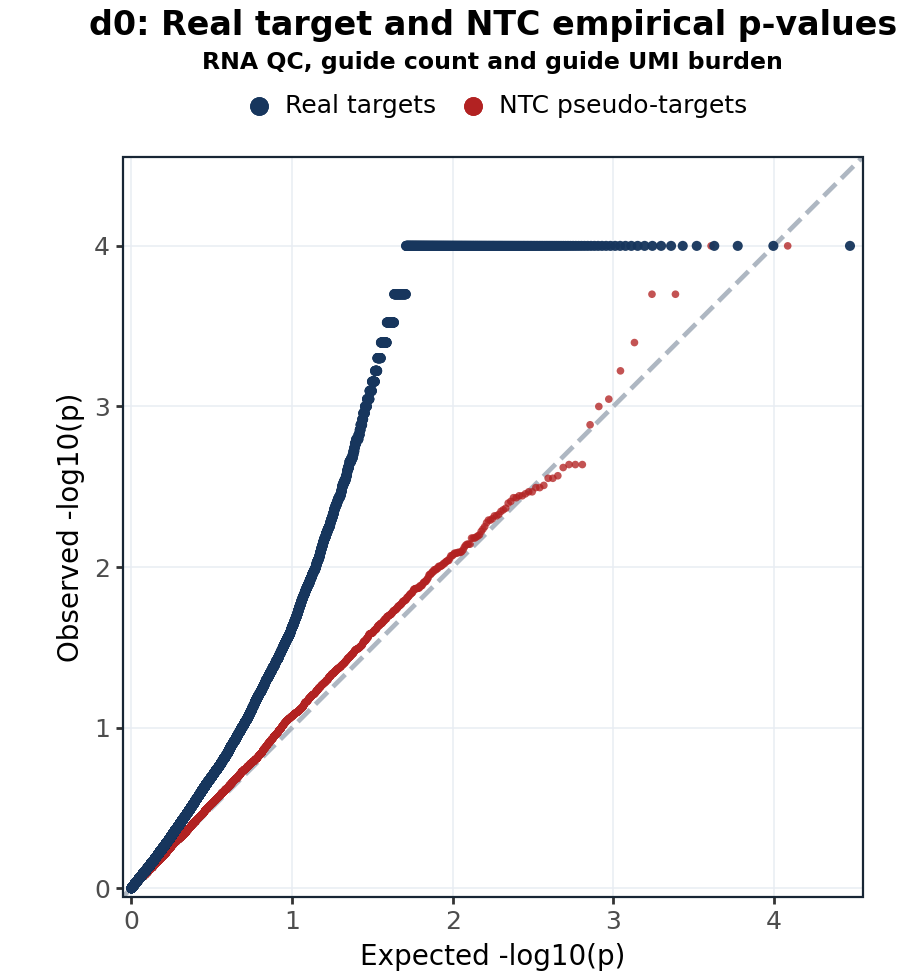

/tmp/ipykernel_36975/622847858.py:58: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


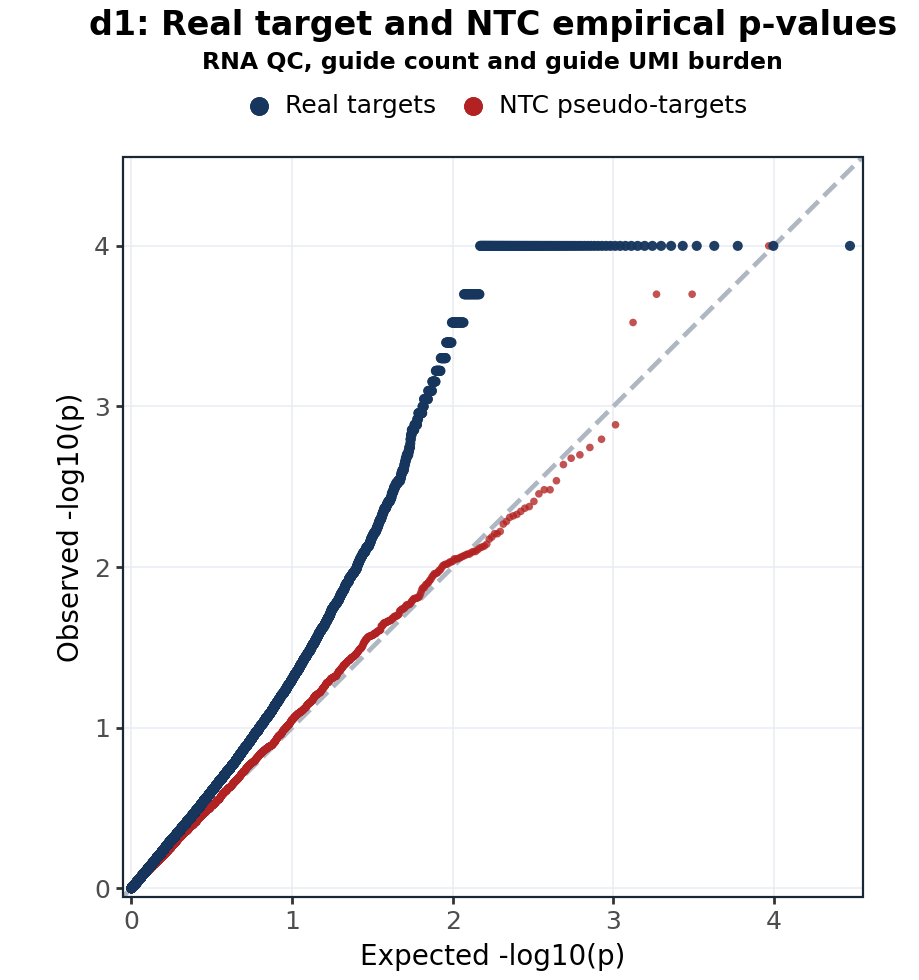

/tmp/ipykernel_36975/622847858.py:58: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


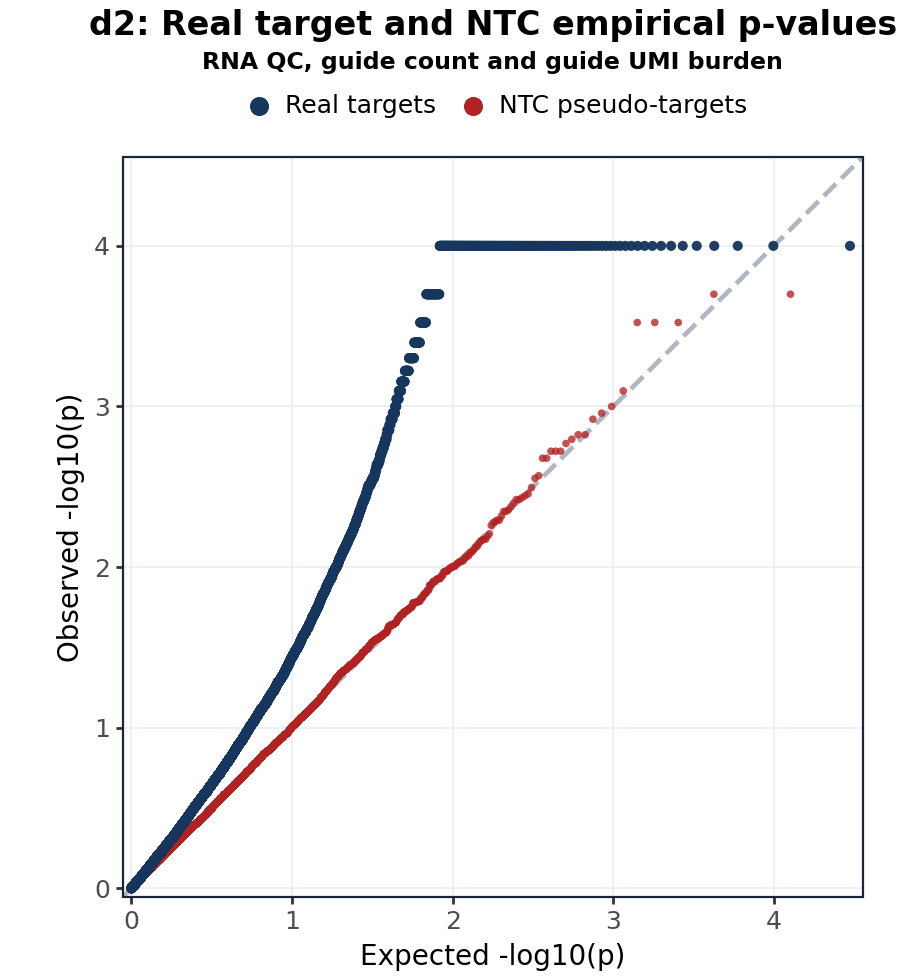

/tmp/ipykernel_36975/622847858.py:58: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


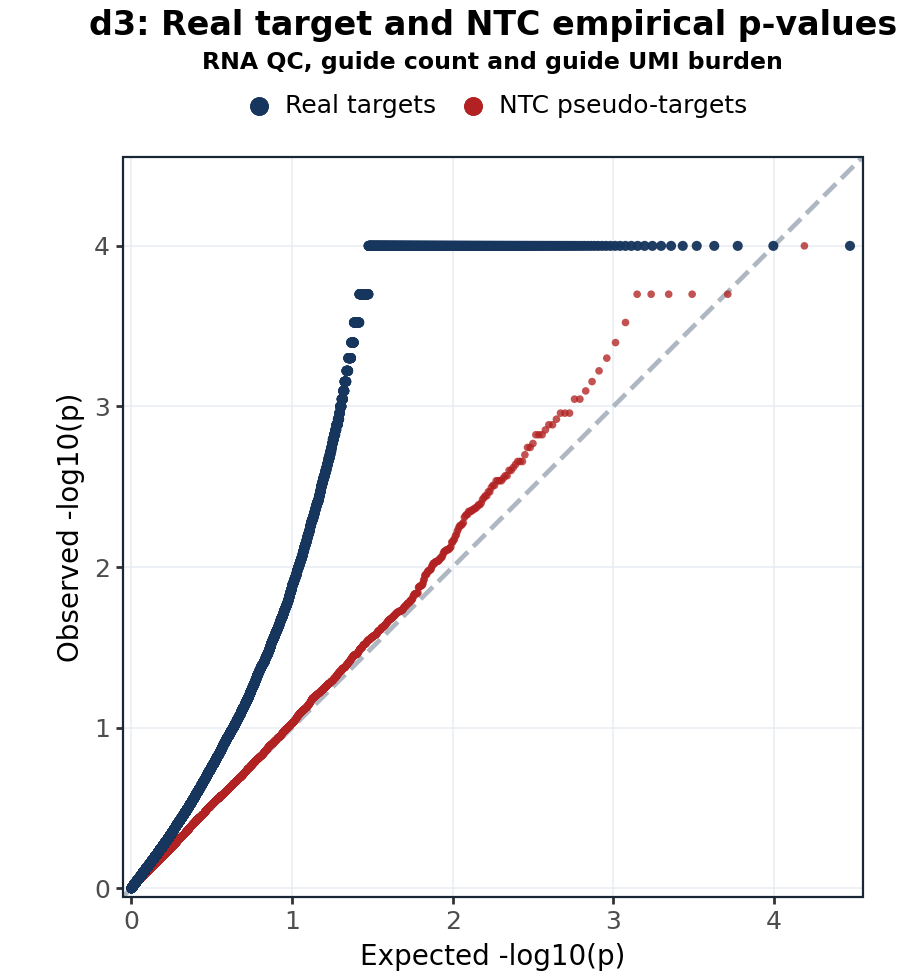

Saved files:

d0
  PDF: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d0_QQ_full_covariates.pdf
  SVG: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d0_QQ_full_covariates.svg
  EPS: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d0_QQ_full_covariates.eps
  PNG: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d0_QQ_full_covariates.png

d1
  PDF: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d1_QQ_full_covariates.pdf
  SVG: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d1_QQ_full_covariates.svg
  EPS: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d1_QQ_full_covariates.eps
  PNG: results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2/illustrator_editable_full_covariates/d1_QQ

In [8]:
qq_csv = MODEL_ROOT / "all_days_QQ_points.csv"
illustrator_out_dir = MODEL_ROOT / "illustrator_editable_full_covariates"

all_saved_files = {}

for day in DAYS:
    p, saved = plot_ipsc_ec_qq(
        qq_csv,
        day=day,
        pvalue_type="empirical",
        title=f"{day}: Real target and NTC empirical p-values",
        subtitle="RNA QC, guide count and guide UMI burden",
        output_stem=illustrator_out_dir / f"{day}_QQ_full_covariates",
        formats=("pdf", "svg", "eps", "png"),
    )
    all_saved_files[day] = saved
    display(p)

print("Saved files:")
for day, files in all_saved_files.items():
    print(f"\n{day}")
    for fmt, path in files.items():
        print(f"  {fmt.upper()}: {path}")
